In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from urllib.request import urlretrieve


In [3]:
UPLOAD_FROM_COMPUTER = False

if UPLOAD_FROM_COMPUTER:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No image was uploaded.")
    filename = list(uploaded.keys())[0]
    image = np.array(Image.open(BytesIO(uploaded[filename])).convert("RGB"))
else:
    # Extract the file ID from the Google Drive sharing link.
    drive_link = "https://drive.google.com/file/d/1sGbOgXlnGZkjLoicFz354wVZEz6SsIwu/view?usp=sharing"
    file_id = drive_link.split("/d/")[1].split("/")[0]
    download_url = "https://drive.google.com/uc?export=download&id=" + file_id

    # Download and read the image. No segmentation is performed here.
    filename = "input_coin.jpg"
    urlretrieve(download_url, filename)
    image = np.array(Image.open(filename).convert("RGB"))

print("Original size:", image.shape[1], "x", image.shape[0], "pixels")

# Take every second pixel for this image to speed up the manual loops.
step = (max(image.shape[:2]) + 479) // 480
image = image[::step, ::step]
print("Processing size:", image.shape[1], "x", image.shape[0], "pixels")


Original size: 676 x 454 pixels
Processing size: 338 x 227 pixels


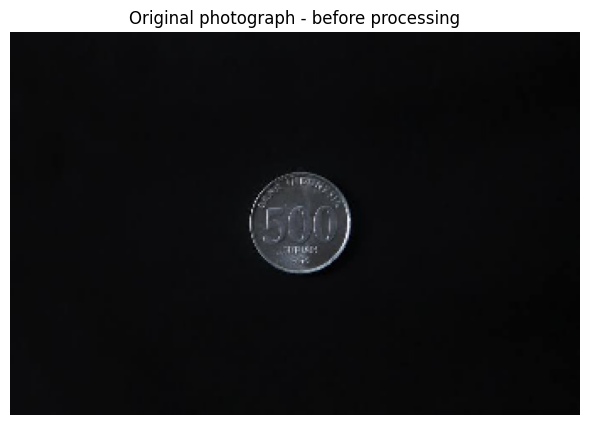

In [4]:
plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title("Original photograph - before processing")
plt.axis("off")
plt.tight_layout()
plt.show()


In [5]:
def grayscale_manual(image):
    height, width = image.shape[:2]
    gray = np.zeros((height, width), dtype=np.uint8)

    for y in range(height):
        for x in range(width):
            r = int(image[y, x, 0])
            g = int(image[y, x, 1])
            b = int(image[y, x, 2])
            gray[y, x] = round(0.299*r + 0.587*g + 0.114*b)

    return gray

gray = grayscale_manual(image)


In [6]:
def threshold_manual(gray, threshold, bright_object=True):
    height, width = gray.shape
    result = np.zeros((height, width), dtype=np.uint8)

    for y in range(height):
        for x in range(width):
            if bright_object:
                is_object = gray[y, x] >= threshold
            else:
                is_object = gray[y, x] < threshold
            if is_object:
                result[y, x] = 255

    return result

THRESHOLD = 40
BRIGHT_OBJECT = True
binary = threshold_manual(gray, THRESHOLD, BRIGHT_OBJECT)


In [7]:
def erosion_manual(image):
    height, width = image.shape
    result = np.zeros((height, width), dtype=np.uint8)

    for y in range(height):
        for x in range(width):
            all_white = True
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    yy = y + dy
                    xx = x + dx
                    if yy < 0 or yy >= height or xx < 0 or xx >= width:
                        all_white = False
                    elif image[yy, xx] == 0:
                        all_white = False
            if all_white:
                result[y, x] = 255

    return result


def dilation_manual(image):
    height, width = image.shape
    result = np.zeros((height, width), dtype=np.uint8)

    for y in range(height):
        for x in range(width):
            any_white = False
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    yy = y + dy
                    xx = x + dx
                    if 0 <= yy < height and 0 <= xx < width:
                        if image[yy, xx] == 255:
                            any_white = True
            if any_white:
                result[y, x] = 255

    return result


In [8]:
def opening_manual(image):
    return dilation_manual(erosion_manual(image))

def closing_manual(image):
    return erosion_manual(dilation_manual(image))

erosion = erosion_manual(binary)
dilation = dilation_manual(binary)
opening = opening_manual(binary)
closing = closing_manual(binary)
combined = closing_manual(opening)


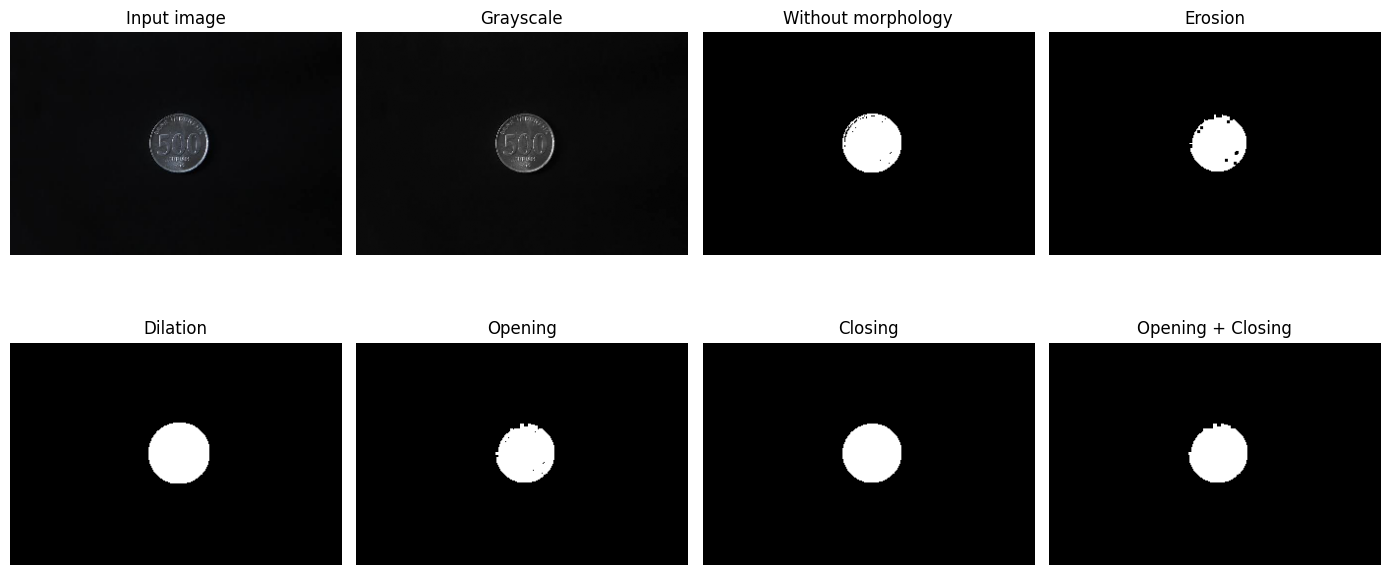

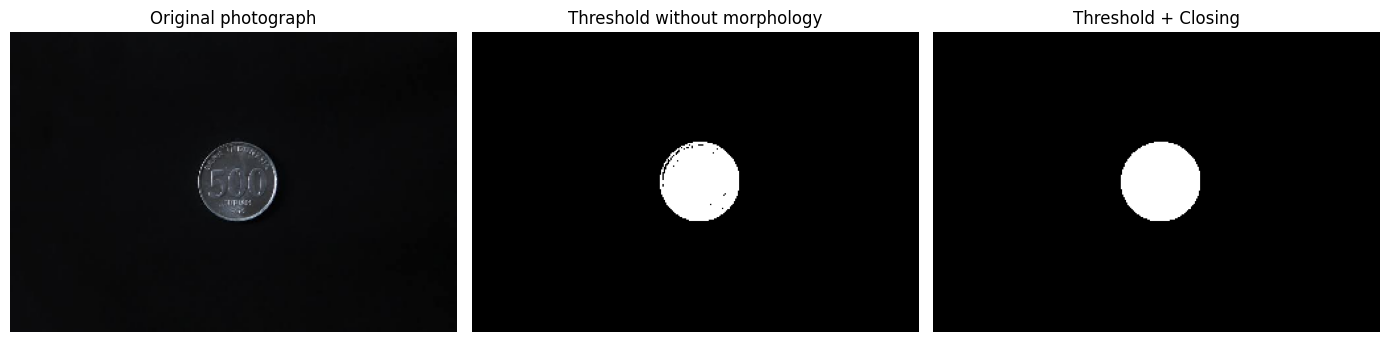

In [9]:
images = [image, gray, binary, erosion, dilation, opening, closing, combined]
titles = ["Input image", "Grayscale", "Without morphology", "Erosion",
         "Dilation", "Opening", "Closing", "Opening + Closing"]

plt.figure(figsize=(14, 7))
for i in range(len(images)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i], cmap="gray", vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis("off")
plt.tight_layout()
plt.show()

# Compare the original photograph with the two segmentation results.
plt.figure(figsize=(14, 4))
comparison_images = [image, binary, closing]
comparison_titles = ["Original photograph", "Threshold without morphology", "Threshold + Closing"]
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(comparison_images[i], cmap="gray", vmin=0, vmax=255)
    plt.title(comparison_titles[i])
    plt.axis("off")
plt.tight_layout()
plt.show()


In [10]:
def count_white(image):
    count = 0
    for y in range(image.shape[0]):
        for x in range(image.shape[1]):
            if image[y, x] == 255:
                count += 1
    return count

def count_differences(image_a, image_b):
    count = 0
    for y in range(image_a.shape[0]):
        for x in range(image_a.shape[1]):
            if image_a[y, x] != image_b[y, x]:
                count += 1
    return count

method_names = ["Without morphology", "Erosion", "Dilation", "Opening", "Closing", "Opening + Closing"]
all_results = [binary, erosion, dilation, opening, closing, combined]

print(f'{"Method":<22} {"White pixels":>14} {"Changed pixels":>16}')
print("-" * 56)
for name, result in zip(method_names, all_results):
    print(f'{name:<22} {count_white(result):>14} {count_differences(binary, result):>16}')

print("\nNo reference mask is provided, so these counts are not accuracy scores.")


Method                   White pixels   Changed pixels
--------------------------------------------------------
Without morphology               2807                0
Erosion                          2419              388
Dilation                         3104              297
Opening                          2720               87
Closing                          2860               53
Opening + Closing                2733               96

No reference mask is provided, so these counts are not accuracy scores.
